**Instructions**
* It is OK to discuss among peers, but it is **not** OK to copy each other's work or each other's functions. 
* The entire work should be done on a Jupyter notebook. Upload the notebook into the assignment submission section of the class moodle. You will need to use markdown cells for typing your answers and code cells to define functions and their run results. 
* In addition to the PDF of the HW, I have also uploaded the notebook for you to take a look at markdown formatting in case you are not sure how to do it. 
* Write your codes paying attention to modularity, generality, and readability. 
* How nice the plots look will carry points. 
* Submit the python notebook also to the moodle. It is OK to download the notebook I have posted and edit it to insert your solutions if you want.

# Question 1 [3 marks]

You probably have already created a github account, created a **private** repository with the name **your_full_name_numerical_methods_2026**, and added your TAs as your collaborators. 
1. Create a .ipynb file within this git repository with the name **your_full_name_HW2_solution.ipynb**
2. After solving each question, `commit` and `push` the changes to github. TAs will look at the commits and history of the notebook. DO NOT just commit and push the final version only.  

[Note: The following are the steps for doing this using `ssh` from `command line` on a `linux`-like system. You create the git repository directly on github.com. This is called the `remote` repo. You can then clone using `ssh` using `git clone <ssh link associated to your remote repo>`. Once cloned, you have a local repo. Any change you make inside the local repo, can then be synched with the remote repo in the following way. E.g., you have created a new file **your_full_name_HW2_solution.ipynb** inside the local repo. Run `git add -A` to add all new files recursively down the directory structure. Run `git commit` to let the repo know that this new file now must be tracked. This will open a text editor such as `vi`. You should write some helpful commit message that let's you know what was this update about. Once commited, run `git push` to push the changes to the remote repo. You are done. Anywan added to your remote repo can now make their clones or update their local version of the repo and be able to follow all historical changes and their commit times and messages. There may be other ways to do the same using GUI-based methods. Fill free to google and choose the method that suits you the best. Also, here is a useful cheat sheet for most of git actions you might want to do. https://education.github.com/git-cheat-sheet-education.pdf]

# Question 2 [5+10+5+4 marks]

1. Write a Python function that can convert a decimal integer number given by the user into a binary.
2. Write a Python function that can convert a user-given real decimal number into its IEEE double floating point machine representation by returning *s* (sign), *e* (exponent), and *f* (mantissa). Remember to pay attention to the special cases. [I found it easier to return $s$, $e$, and $f$ as character strings where each character can be '0' or '1'].
3. Write a Python function that can convert a machine floating point representation given by the user by supplying *s*, *e*, and *f*, into a real decimal number. Remember to take care of the special cases.
4. Verify the accuracy of the functions by using *2* and *3* on the following real numbers-
    1. 200.0
    2. $\pi$
    3. $+\infty$
    4. $-\infty$
    

In [1]:
#Part 1

import numpy as np

n = 1927   #Binary no. to be converted into decimals
lr = [] #Define an empty list of remainders

#Now we collect all the remainders following the long division process
while n//2 > 0:
    r = n%2
    lr.append(r)
    n = n//2
    
#As we can notice, the last 1 is always missed because the while loop just breaks due to n//2 without collecting r=1.
lr.append(1)

#Now, finally we reverse the list (same as reading the remainders from bottom to top)
lr_new = []
for i in range(len(lr)):
    lr_new.append(lr[-1-i])
print(lr_new)

[1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1]


In [3]:
#Part 2
import math

def decimal_to_ieee754(x):
    # Handle the sign bit first
    # Using 1/x rule to catch a negative zero (-0.0) safely
    if x == 0.0:
        s = "1" if math.copysign(1.0, x) < 0.0 else "0"
        return s, "0"*11, "0"*52
        
    if x < 0:
        s = "1"
        x = -x
    else:
        s = "0"
        
    # Handle the infinite values
    if x == float('inf'):
        return s, "1"*11, "0"*52
    if x != x: # Standard trick for checking NaN (Not a Number)
        return s, "1"*11, "1" + "0"*51

    # Separating the integer part and the fractional part
    int_part = int(x)
    frac_part = x - int_part
    
    # Converting integer part to binary list (same loop logic as your Part 1)
    l_int = []
    if int_part == 0:
        l_int = [0]
    else:
        temp = int_part
        while temp // 2 > 0:
            l_int.append(temp % 2)
            temp = temp // 2
        l_int.append(1)

        l_int_rev = []                #and finally reversing the list
        for i in range(len(l_int)):
            l_int_rev.append(l_int[-1-i])
        l_int = l_int_rev

    l_frac = []                       #Converting fractional part to binary list
    while frac_part > 0 and len(l_frac) < 1050: # Limit prevents infinite loops
        frac_part = frac_part * 2
        bit = int(frac_part)
        l_frac.append(bit)
        frac_part = frac_part - bit

    # Locating where the first '1' appears to set our scientific notation scale
    if int_part > 0:
        # First '1' is inside the integer part
        first_one_pos = 0
        # Combine them into a full bits timeline
        combined_bits = l_int + l_frac
        exponent_actual = len(l_int) - 1
    else:
        # First '1' must be inside the fractional part
        first_one_pos = -1
        for i in range(len(l_frac)):
            if l_frac[i] == 1:
                first_one_pos = i
                break
        
        if first_one_pos == -1: # True fallback if it's zero
            return s, "0"*11, "0"*52
            
        combined_bits = l_frac[first_one_pos:]
        exponent_actual = -(first_one_pos + 1)

    # Check if number is too close to zero
    biased_exp = exponent_actual + 1023
    
    f_list = []
    if biased_exp <= 0:
        # Subnormal logic adjustments
        biased_exp = 0
        # Re-slice bits based on the minimum subnormal window scale
        bits_needed = x * (2**1074)
        int_bits = int(round(bits_needed))
        # Build binary string manually
        f_str = ""
        for i in range(52):
            f_str = str(int_bits % 2) + f_str
            int_bits //= 2
        e_str = "0"*11
        return s, e_str, f_str
    
    # Extracting the 52 mantissa bits (skipping the very first hidden '1')
    for i in range(1, 53):
        if i < len(combined_bits):
            f_list.append(str(combined_bits[i]))
        else:
            f_list.append("0") # pad trailing spaces with zero
            
    f_str = "".join(f_list)
    
    # Convert biased exponent integer into 11-bit binary string manually
    e_list = []
    temp_e = biased_exp
    while temp_e // 2 > 0:
        e_list.append(str(temp_e % 2))
        temp_e = temp_e // 2
    if biased_exp > 0:
        e_list.append("1")
    
    # Pad up to 11 bits and reverse manual step
    while len(e_list) < 11:
        e_list.append("0")
        
    e_str_rev = []
    for i in range(len(e_list)):
        e_str_rev.append(e_list[-1-i])
    e_str = "".join(e_str_rev)
    
    return s, e_str, f_str

In [4]:
#Part 3

def ieee754_to_decimal(s, e, f):
    # Process sign bit string multiplier
    if s == "1":
        sign = -1.0
    else:
        sign = 1.0
        
    # Convert exponent bit string back to an integer value manually
    biased_exp = 0
    for i in range(len(e)):
        bit = int(e[i])
        power = len(e) - 1 - i
        biased_exp += bit * (2**power)
        
    # Convert mantissa bit string fractions back to decimal values manually
    mantissa_fraction = 0.0
    for i in range(len(f)):
        bit = int(f[i])
        power = -(i + 1)
        mantissa_fraction += bit * (2**power)
        
    # Case A: Special values (Exponent is all 1s -> 2047)
    if biased_exp == 2047:
        if mantissa_fraction == 0.0:
            return float('-inf') if s == "1" else float('inf')
        else:
            return float('nan')
            
    # Case B: Subnormal or Zero Values (Exponent is all 0s)
    if biased_exp == 0:
        if mantissa_fraction == 0.0:
            return sign * 0.0
        # Subnormal arithmetic calculation formula
        return sign * mantissa_fraction * (2**-1022)
        
    # Case C: Standard Normal floating points
    actual_exponent = biased_exp - 1023
    total_val = 1.0 + mantissa_fraction
    
    return sign * total_val * (2**actual_exponent)

In [5]:
#Part 4

import numpy as np

# Setting up test inputs cases
cases = [
    ("Case 1 (200.0)", 200.0),
    ("Case 2 (Pi)", np.pi),
    ("Case 3 (+Infinity)", float('inf')),
    ("Case 4 (-Infinity)", float('-inf'))
]

# Run values through our conversions loop
for name, val in cases:
    # 1. Pack down to bits representation strings
    s, e, f = decimal_to_ieee754(val)
    
    # 2. Unpack bits back to decimal floats
    reconstructed = ieee754_to_decimal(s, e, f)
    
    print("----------------------------------------")
    print("Target:", name)
    print("Sign bit string: ", s)
    print("Exp bit string:  ", e)
    print("Mantissa snippet:", f[:10] + "...")
    print("Recovered Float: ", reconstructed)

----------------------------------------
Target: Case 1 (200.0)
Sign bit string:  0
Exp bit string:   10000000110
Mantissa snippet: 1001000000...
Recovered Float:  200.0
----------------------------------------
Target: Case 2 (Pi)
Sign bit string:  0
Exp bit string:   10000000000
Mantissa snippet: 1001001000...
Recovered Float:  3.141592653589793
----------------------------------------
Target: Case 3 (+Infinity)
Sign bit string:  0
Exp bit string:   11111111111
Mantissa snippet: 0000000000...
Recovered Float:  inf
----------------------------------------
Target: Case 4 (-Infinity)
Sign bit string:  1
Exp bit string:   11111111111
Mantissa snippet: 0000000000...
Recovered Float:  -inf


# Question 3 [(2+2)+(2+2+2)+4+2]

We will create an experiment that will illustrate what is often called *error crip* in numerical methods. 

Consider, you have a grid between $a$ and $b$ with a total of $n$ equally spaced gridpoints. Clearly, the spacing between gridpoints would be $h=(b-a)/(n-1)$. There are two ways you can create the grid points. 

**Method 1**
The $i$th gridpoint is

$g_i = a+i*h$. 

**Method 2**
Populate the gridpoints via the reccurrence relation of the form-

$g_{i}=g_{i-1}+h$. 

1. Write two functions `method1` and `method2` using the above algorithms which returns the gridpoints `gs`. The arguments to each of these functions should be $a$, $b$, and $n$. Make sure that `gs[0]=a` and `gs[-1]=b`.  
2. Using $a=1$, $b=10$, and $n=10^6$, find the average of the gridpoints-
    1. analytically ($\bar{g_a}$). 
    2. using `method1` ($\bar{g_1}$). 
    3. using `method2` ($\bar{g_2}$).
3. Calculate $\Delta_1\equiv|\bar{g_a}-\bar{g_1}|$ and $\Delta_2\equiv|\bar{g_a}-\bar{g_2}|$ for $n=10, 100, 10^3, 10^4, 10^5, 10^6, 10^7, 10^8$. Plot $n$ vs $\Delta_1$ and $\Delta_2$. 
4. Is one of these methods more accurate than the other? Explain why.

In [6]:
# Part 1:

# Method 1
def func1(a,b,n):
    lg = []             #list of grid points
    h=(b-a)/(n-1)
    for i in range(n):
        lg.append(a + i*h)
    return(lg)

# Method 2
def func2(a,b,n):       
    a=float(a)
    lg = [a]            #list of grid points
    h=(b-a)/(n-1)
    for i in range(n-1):
        lg.append(lg[-1]+h)
    return(lg)

lg1 = func1(2,5,4)
lg2 = func2(2,5,4)
print(lg1)
print(lg2)

[2.0, 3.0, 4.0, 5.0]
[2.0, 3.0, 4.0, 5.0]


In [7]:
# Part 2:

# A. Analytically

def funcn_analytical(a=1, b=10, n=int(1e6)):
    sum = 0
    h = (b-a)/(n-1)
    for i in range(n):      
        grid_pt = a + i*h           #Manually adding all the grid points one by one
        sum = sum+grid_pt
    average = sum/n
    return average
print("The analytical average is",funcn_analytical(1, 10, int(1e6)))

sum=0
del(sum)   #We use sum() function in python. so deleting the variable sum(defined somewhere earlier) must be deleted.
# B. Method 1
lg1 = func1(1,10, int(1e6))
avg1 = sum(lg1)/1e6
print("The method 1 average is",avg1)

# C. Method 2
lg2 = func2(1,10, int(1e6))
avg2 = sum(lg2)/1e6
print("The method2 average is",avg2)

The analytical average is 5.5
The method 1 average is 5.5
The method2 average is 5.500000000014386


In [10]:
# Part 3
# I'm not plotting n=128 because it is out of memory capacity of my system.
list_n = [10, 100, 1000, 10000, 100000, 1000000, 10000000]

err_method1 = []
err_method2 = []

# Clear out any overwritten built-in sum variable if it exists in your notebook
try:
    del sum
except NameError:
    pass

# Running a for loop to fill the error lists.
for i in list_n:
    
    lg1 = func1(a=1, b=10, n=i)
    lg2 = func2(a=1, b=10, n=i)  # Fixed: changed from func1 to func2
    
    s1 = sum(lg1) / len(lg1)
    s2 = sum(lg2) / len(lg2)
    
    f_value = funcn_analytical(a=1, b=10, n=i)
    
    err_method1.append(abs(s1 - f_value))
    err_method2.append(abs(s2 - f_value))  # Fixed: changed from s1 to s2
    
print("delta1 is", err_method1)
print("delta2 is", err_method2)

delta1 is [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
delta2 is [0.0, 3.552713678800501e-15, 5.1514348342607263e-14, 3.979039320256561e-13, 5.079492382265016e-12, 1.4385825863882928e-11, 7.203206919825789e-10]


I discarded method1 plot because in my case analytic function and method1 plot give identical sums.
So, Delta2 Errors are identically zero.


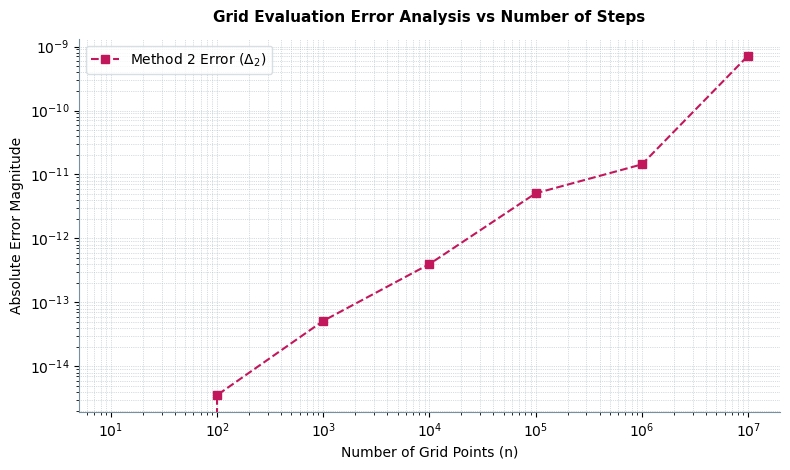

In [20]:
#Creating a nice matplotlib plot for part 3
print("I discarded method1 plot because in my case analytic function and method1 plot give identical sums.")
print("So, Delta2 Errors are identically zero.")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.set_facecolor('#ffffff')

ax.plot(list_n, err_method2, color='#c2185b', linestyle='--', linewidth=1.5, 
        marker='s', label='Method 2 Error ($\Delta_2$)')

#let's use log scales
ax.set_xscale('log')
ax.set_yscale('log')

ax.set_title('Grid Evaluation Error Analysis vs Number of Steps', fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel('Number of Grid Points (n)', fontsize=10)
ax.set_ylabel('Absolute Error Magnitude', fontsize=10)

ax.grid(True, which="both", linestyle=':', linewidth=0.5, color='#b0bec5')

# Un-boxing look: Remove top and right boundary lines (a classic custom code style)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.spines['left'].set_color('#78909c')
ax.spines['bottom'].set_color('#78909c')

ax.legend(loc='best', frameon=True, edgecolor='#cfd8dc')
plt.tight_layout()
plt.show()

# Question 4 [2+2+5+2+2+2 marks]

In the class we discussed how sometimes it is essential to write your espressions in a machine-safe way. We will see this using an example here. Consider a quadratic equation of the form $ax^2+bx+c=0$. We know that there are two solutions, $x^0_\pm = \dfrac{-b\pm\sqrt{b^2-4ac}}{2a}$. Assume, $b^2>4ac$, so $x^0_\pm$ are both real.

1. Write a function that takes $a$, $b$, and $c$ as inputs and gives back $x^0_\pm$ as output using the above expression.    

2. Discuss a possible problem if $b^2\gg4ac$. 

3. Can you find a way to handle the situation $b^2\gg4ac$ better? Show calculations as appropriate. [Hint: One of the solutions is safe even when $b^2\gg4ac$. Is there a way to find the safe solution and then find the other one using it?]    

4. Write a function using the new method to estimate $x^0_\pm$. 

5. Test the following cases and comment on the behaviour of the two codes. Which is better?     
    (a) $x^0_\pm = 1, 2$     
    (b) $x^0_\pm = 10^{-8}, 10^{8}$

In [2]:
# Part 1
import numpy as np

def func_quad(a,b,c):
    x_minus = (-b - np.sqrt(b**2 - 4*a*c))/(2*a)
    x_plus = (-b + np.sqrt(b**2 - 4*a*c))/(2*a)
    return x_minus, x_plus

In [4]:
x1,x2=func_quad(1, -3, 2)
print("x1 = "+str(x1))  # Example usage
print("x2 = "+str(x2))  # Example usage

x1 = 1.0
x2 = 2.0


* When the discriminant is negative, the roots will not be real. Your function should account for this situation. As well as D=0 situation too.
\
+1

#Part 2

The fundamental issue with b^2 >> 4ac is that when this is true then square root essentially ejects |b| out.
x safe is when square root term and -b add up.
x unsafe is when -b and sqrt term cancel. (catestrophic cancellation of many significant digits) This essentially presents the numerical rounding noise as the answer (which is of course the wrong answer).

I will demonstrate a comparison with the corrected method in subsequent parts: -

+2

In [5]:
# Part 3 and Part 4

#One of the solution is safe when the numerators obey an adding law (and no cancelling behaviour). Using sqrt(b^2) = |b|
#when b<0 then -b + sqrt(b^2) gives x safe (|b|=-b)
#when b>0 then -b - sqrt(b^2) gives x safe (|b|=+b)

def func_quad_safer(a,b,c):
    D = b**2 - 4*a*c
    
    if b>=0:       #Defining sigmum function with respect to b.
        sgn=+1;
    else:
        sgn=-1;
        
    x_safe = (-b - sgn*np.sqrt(D))/(2*a)
    
    # We know that x1x2 = c/a
    x_unsafe = c/(a*x_safe)
        
    # It is easy to notice that if b>0 then x_safe is x_minus and if b<0 then x_safe is x_plus
    if sgn==+1:
        x_minus=x_safe
        x_plus=x_unsafe
    else:
        x_minus=x_unsafe
        x_plus=x_safe
    return x_minus, x_plus

+5
\
+2

In [6]:
# Part 5

#Let us find the quadratic equations corresponding to the given cases and test our functions. x^2 -(x1+x2)x +x1x2 = 0.

#Case 1: x1=1, x2=2. Then x^2 - 3x + 2.
#here a=1, b=-3, c=2. b^2-4ac = 1 (not too big). So both the methods should work well

x1_1, x2_1 = func_quad(1, -3, 2)
x1_2, x2_2 = func_quad_safer(1, -3, 2)
print("for the quad eqn x^2 -3x +2 = 0")
print("x- is",x1_1,"and x+", x2_1)
print("x- is",x1_2,"and x+", x2_2, '\n')

#Case 2: x1=1e-8, x2=1e8. Then x^2 - (1e-8 + 1e8)x + 1.
#here a=1, b=(approximately) 1e8, c=1. b^2-4ac = 1e8 (darn big). So method 1 may likely fail.
x1_1, x2_1 = func_quad(1, 1e8 + 1e-8, 1)
x1_2, x2_2 = func_quad_safer(1, 1e8 + 1e-8, 1)
print("for the quad eqn x^2 -(1e8 + 1e-8)x +1 = 0")
print("x- is",x1_1,"and x+", x2_1)
print("x- is",x1_2,"and x+", x2_2,'\n')
print("Certainly, the second one is better as expected.")

for the quad eqn x^2 -3x +2 = 0
x- is 1.0 and x+ 2.0
x- is 1.0 and x+ 2.0 

for the quad eqn x^2 -(1e8 + 1e-8)x +1 = 0
x- is -100000000.0 and x+ -1.4901161193847656e-08
x- is -100000000.0 and x+ -1e-08 

Certainly, the second one is better as expected.


+2
\
+2
* Very nice.

In [7]:
q4=1+2+5+2+2+2
print(q4)

14


# Question 5 [2+2+2+4+1+5+4+4+6+4+6+2 marks]

Consider $f(x) = e^{x}$. We know that the Taylor series expansion is 
$f(x) = 1 + x + \dfrac{x^2}{2!} + \dfrac{x^3}{3!} + \dfrac{x^4}{4!} + \dfrac{x^5}{5!} + \dots$. In this problem, we will try to write a code that can calculate $f(x)$ using the Taylor series. 

1. Write a function that calculates and returns the factorial of an integer. 
2. Write a function that takes the number of terms in the series to sum, $N$, and evaluates $f(x)$ for a given value of $x$, approximated upto the first $N$ number of terms. 
3. Evaluate $f(x)$ using the above functions for $x=20$ and $N=100$. 
4. Note that the $n$th term of the series can be found from the $(n-1)$th term of the series using the reccurrence relation $t_{n} = t_{n-1} \times \dfrac{x}{n}$. Use of this reccurrence relation saves you from tedious factorial calculations. Write a function that uses this reccurrence relation to evaluate $f(x)$ for a given $N$ and $x$. This function should also return the individual terms of the series, $t_n$, the partial sums $S_n=\sum^{n}_{i=0} t_i$, and $n$ in separate lists (or arrays).  
5. Evaluate $f(x)$ for $x=20$ and $N=100$ using the new function. 
6. Using a suitable function from `numpy` evaluate $e^{20}$. Let's call this $E20_+$. Plot $t_n$ and $S_n$ as a function of $n$. Also show $E20_+$ on the same figure using a horizontal line spanning the whole figure. Does $S_n$ approach $E20_+$ for a sufficiently high $n$? 
7. Plot $\Delta_{20, n} = |S_n - E20_+|$ as a function of $n$. Does it decrease as you increase $n$? 
8. Using the function written by you in part 4, calculate $f(x)$ at $x=-20$ using $N=100$.    
9. Using `numpy`, find $e^{-20}\equiv E20_-$. Plot $t_n$ and $S_n$ as a function of $n$. Also show $E20_-$ on the same figure using a horizontal line spanning the whole figure. Does $S_n$ approach $E20_-$ for a sufficently high $n$? 
10. Plot $\Delta_{-20, n} = |S_n - E20_-|$ as a function of $n$. Does it decrease as you increase $n$? 
11. Let's say, $\delta_+$ and $\delta_-$ are the absolute value of the relative errors between the values obtained using `numpy` and your function for $e^{20}$ and $e^{-20}$, respectively (using $N=100$). Assuming values obtained from `numpy` are correct, report these. Which evaluation was done better? Why this difference? 
12. Modify your function in part 4 that will allow you to evaluate the current worse case with a much better level of accuracy. Prove that this works. 

In [23]:
# Part 1
def fact(N):
    if N>0:
        i=1
        factorial=1
        while i<=N:
            factorial=factorial*i
            i+=1
    elif N==0:
        factorial=1
    else:
        factorial="Factorial is only defined for integers >= 0!" # this line was wrong
    return factorial

In [22]:
print(fact(3))

6


* The code is written in such a way that it is handling negative values well but fails for +ve fractions. It is always returning the factorial for the least int value of N. It should show some error for those.
\
+1

In [24]:
# Part 2

# N is the no. of terms in Taylor Expansion from now onwards.

def f_taylor(x,N):
    
    s=0
    i=0
    while i<=N-1:
        s = s + (x**i)/fact(i)
        i+=1
    return(s)

+2

In [47]:
# Part 3
print(f_taylor(20,100))

485165195.40979016


+2

In [27]:
# Part 4

# N is the no. of terms in Taylor Expansion.

def f_taylor_rec(x,N):
    s = 0
    i = 0
    term = 1                     # some initial value that helps us make sense of the following code.
    
    listofterms = [term]
    listofpartialsums = []
    
    while i<N:
        i+=1     
        s = s+term
        listofpartialsums.append(s)
        
        mf = x/i                  # mf = multipying factor
        term = term*mf
        listofterms.append(term)
    listofterms.pop()             # realise, we defined listofterms=[1] (not an empty list!)
        
    return s, listofterms, listofpartialsums

+4

In [28]:
# Part 5
s, listofterms, listofpartialsums = f_taylor_rec(1,100)
print(s)

2.7182818284590455


+1

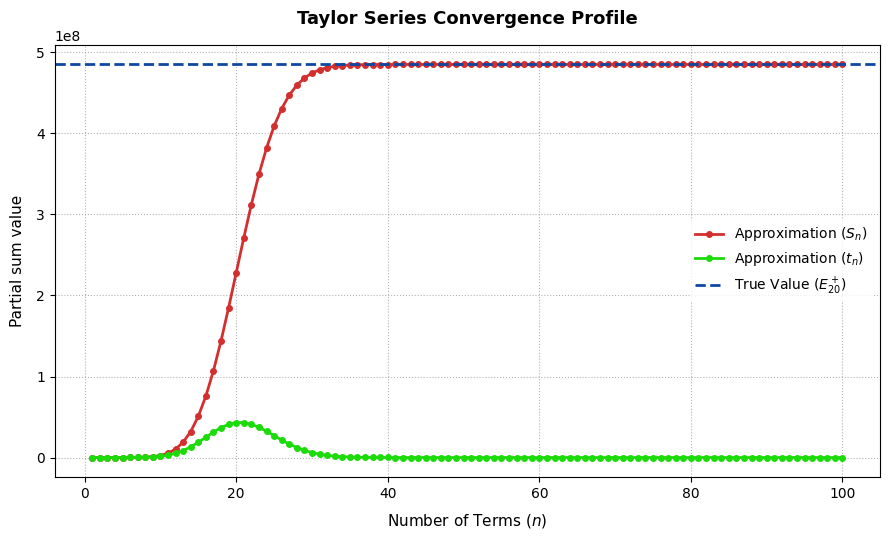

In [30]:
# Part 6
import numpy as np
import matplotlib.pyplot as plt

E20_plus = np.exp(20)        #Numpy function to calculate exp(20).
s, listofterms, listofpartialsums = f_taylor_rec(20,100)  #using our previously defined function to generate partial sums data

i=1
N=100                        #let N be sufficiantly enough terms
n_values=[]                  #creating a list of n_values
while i<=N:
        n_values.append(i)
        i+=1

#Creating a nice matplotlib plot.
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=100)
ax.plot(n_values, listofpartialsums, color='#d32f2f', linestyle='-', linewidth=2, 
        marker='o', markersize=4, label='Approximation ($S_n$)')
ax.plot(n_values, listofterms, color="#1ddb0b", linestyle='-', linewidth=2, 
        marker='o', markersize=4, label='Approximation ($t_n$)')
ax.axhline(y=E20_plus, color='#0d47a1', linestyle='--', linewidth=2, 
           label='True Value ($E_{20}^+$)')

ax.set_title('Taylor Series Convergence Profile', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Number of Terms ($n$)', fontsize=11, labelpad=8)
ax.set_ylabel('Partial sum value', fontsize=11, labelpad=8)

ax.grid(True, linestyle=':', alpha=0.6, color='gray') # Subtle background grid
ax.legend(loc='best', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

* You did not plot $t_n$ vs $n$
\
+4

Yes, E20+ does approach the numpy calculated value as n becomes sufficiently large.


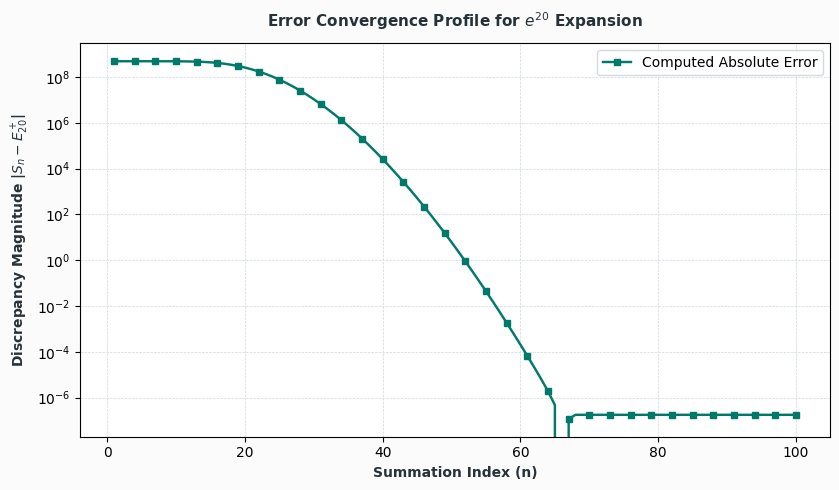

The amomaly around n=65 must be an accidentally lucky scenerio when the error is too less.


In [31]:
#Part 7
import numpy as np
import matplotlib.pyplot as plt

i=1
N=100                        #let N be sufficiantly enough terms
n_values=[]                  #creating a list of n_values
errors = []                  #an empty list of errors

while i<=N:
        n_values.append(i)
        errors.append(abs(listofpartialsums[i-1] - E20_plus))
        i+=1
        
print("Yes, E20+ does approach the numpy calculated value as n becomes sufficiently large.")

fig, ax = plt.subplots(figsize=(8.5, 5), facecolor='#fbfbfb') # Off-white background canvas
ax.set_facecolor('#ffffff')

ax.plot(n_values, errors, color='#00796b', linestyle='-', linewidth=1.75, 
        marker='s', markersize=4, markevery=3, label='Computed Absolute Error')

ax.set_yscale('log') #setitng the scale to log is important for visualization
ax.set_xlabel('Summation Index (n)', fontsize=10, fontweight='bold', color='#263238')
ax.set_ylabel('Discrepancy Magnitude |$S_n - E_{20}^+$|', fontsize=10, fontweight='bold', color='#263238')
ax.set_title('Error Convergence Profile for $e^{20}$ Expansion', fontsize=11, fontweight='bold', pad=12, color='#263238')

ax.grid(True, which="both", linestyle='--', linewidth=0.5, color='#cfd8dc')
ax.legend(loc='upper right', framealpha=0.9, edgecolor='#cfd8dc')
plt.tight_layout()
plt.show()

print("The amomaly around n=65 must be an accidentally lucky scenerio when the error is too less.")

* Write down the fact that after a certain number of terms the accuracy is no longer getting better due to finite machine precision.
\
+3.5

In [32]:
#Part 8

s1, listofterms1, listofpartialsums1 = f_taylor_rec(-20,100)
print("The valuse of exp(-20) upto 100 terms is" ,s1)

The valuse of exp(-20) upto 100 terms is 6.147561828914626e-09


+4

Yes, E20- does approach the numpy calculated value as n becomes sufficiently large.


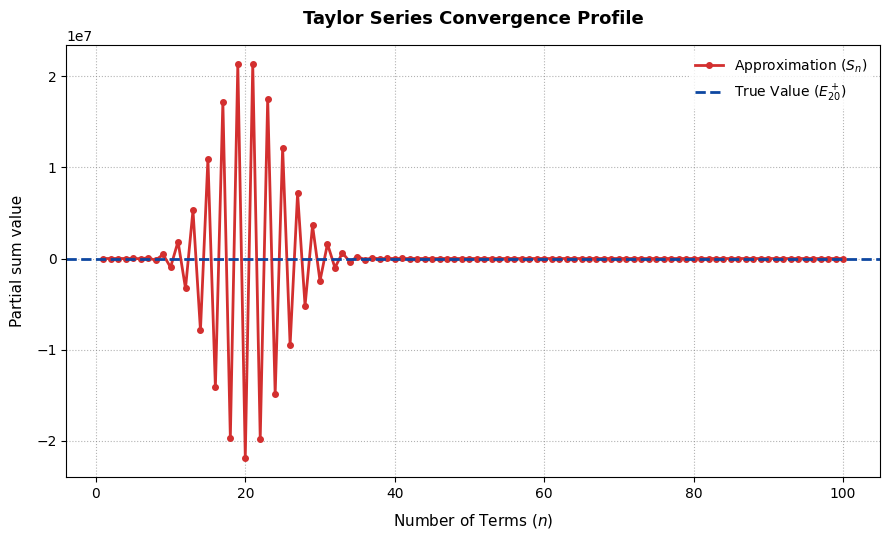

In [33]:
#Part 9

import numpy as np
import matplotlib.pyplot as plt

E20_minus = np.exp(-20)        #Numpy function to calculate exp(-20).
s1, listofterms1, listofpartialsums1 = f_taylor_rec(-20,100)  #using our previously defined function to generate partial sums data

i=1
N=100                        #let N be sufficiantly enough terms
n_values=[]                  #creating a list of n_values
while i<=N:
        n_values.append(i)
        i+=1
        
print("Yes, E20- does approach the numpy calculated value as n becomes sufficiently large.")

#Creating a nice matplotlib plot.
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=100)
ax.plot(n_values, listofpartialsums1, color='#d32f2f', linestyle='-', linewidth=2, 
        marker='o', markersize=4, label='Approximation ($S_n$)')
ax.axhline(y=E20_minus, color='#0d47a1', linestyle='--', linewidth=2, 
           label='True Value ($E_{20}^+$)')

ax.set_title('Taylor Series Convergence Profile', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Number of Terms ($n$)', fontsize=11, labelpad=8)
ax.set_ylabel('Partial sum value', fontsize=11, labelpad=8)

ax.grid(True, linestyle=':', alpha=0.6, color='gray') # Subtle background grid
ax.legend(loc='best', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

* You did not plot $t_n$ vs n.
* Use a logscale along y axis to show that term and partial sum are converging at different points.
\
+4

Yes, E20- does approach the numpy calculated value as n becomes sufficiently large.


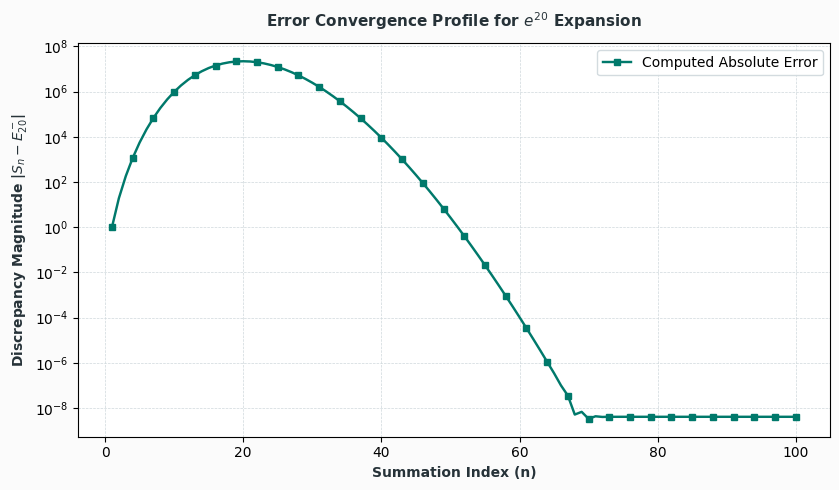

In [35]:
#Part 10

i=1
N=100                        #let N be sufficiantly enough terms
n_values=[]                  #creating a list of n_values
errors1 = []                  #an empty list of errors

while i<=N:
        n_values.append(i)
        errors1.append(abs(listofpartialsums1[i-1] - E20_minus))
        i+=1
        
print("Yes, E20- does approach the numpy calculated value as n becomes sufficiently large.")

fig, ax = plt.subplots(figsize=(8.5, 5), facecolor='#fbfbfb') # Off-white background canvas
ax.set_facecolor('#ffffff')

ax.plot(n_values, errors1, color='#00796b', linestyle='-', linewidth=1.75, 
        marker='s', markersize=4, markevery=3, label='Computed Absolute Error')

ax.set_yscale('log') #setitng the scale to log is important for visualization
ax.set_xlabel('Summation Index (n)', fontsize=10, fontweight='bold', color='#263238')
ax.set_ylabel('Discrepancy Magnitude |$S_n - E_{20}^-$|', fontsize=10, fontweight='bold', color='#263238')
ax.set_title('Error Convergence Profile for $e^{20}$ Expansion', fontsize=11, fontweight='bold', pad=12, color='#263238')

ax.grid(True, which="both", linestyle='--', linewidth=0.5, color='#cfd8dc')
ax.legend(loc='upper right', framealpha=0.9, edgecolor='#cfd8dc')
plt.tight_layout()
plt.show()

+4

In [37]:
# Part 11

s, listofterms, listofpartialsums = f_taylor_rec(20,100)
s1, listofterms1, listofpartialsums1 = f_taylor_rec(-20,100)

error_E20_plus = abs(s-np.exp(20))/np.exp(20)
error_E20_minus = abs(s1-np.exp(-20))/np.exp(-20)

print("The error in E20+ at N=100 is", error_E20_plus)
print("The error in E20- at N=100 is", error_E20_minus,'\n')

print("The error in E20- is much larger than the error in E20+. This is because E20- contains terms of alternative + and -",
      "signs that lead to catestrophic cancellation of terms and forces python to discard significant digits.")

The error in E20+ at N=100 is 3.685629884788795e-16
The error in E20- at N=100 is 1.9825830360191323 

The error in E20- is much larger than the error in E20+. This is because E20- contains terms of alternative + and - signs that lead to catestrophic cancellation of terms and forces python to discard significant digits.


+6

In [46]:
# Part 12

print("As it was explained in the class, the easiest manner to surmount this issue is try to avoid catestrophic cancellation.")
print("This can be done purely by the means of mathematics:-     np.exp(-20) = np.exp(20)-1")

def safer_negative_exponent(x,N):
    s, listofterms, listofpartialsums = f_taylor_rec(-x,N)
    reciprocal = 1/s
    return reciprocal

e20_minus = safer_negative_exponent(-20,100)
print("The relative error in safer version of our function is", abs(e20_minus-np.exp(-20))/np.exp(-20), "(too good!)") 


As it was explained in the class, the easiest manner to surmount this issue is try to avoid catestrophic cancellation.
This can be done purely by the means of mathematics:-     np.exp(-20) = np.exp(20)-1
The relative error in safer version of our function is 4.013192435284797e-16 (too good!)


* What you printed is not relative error but absolute error. I have fixed that.
\
+2

In [49]:
q5=1+2+2+4+1+4+3.5+4+4+4+6+2
print(q5)

37.5
